# OpenCV 입력 처리 Tutorial

OpenCV에서 이미지, 동영상, 카메라 입력을 처리하는 방법을 학습하기 위한 가이드입니다.

## 목차
1. [이미지 입력 처리](#1-이미지-입력-처리)
2. [동영상 파일 입력 처리](#2-동영상-파일-입력-처리)
3. [카메라(웹캠) 입력 처리](#3-카메라웹캠-입력-처리)
4. [공통 전처리 함수](#4-공통-전처리-함수)
5. [실습 예제](#5-실습-예제)

---

## 1. 이미지 입력 처리

### 필요한 라이브러리 import

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob

### 기본 이미지 읽기

Image size: (1080, 1618, 3)


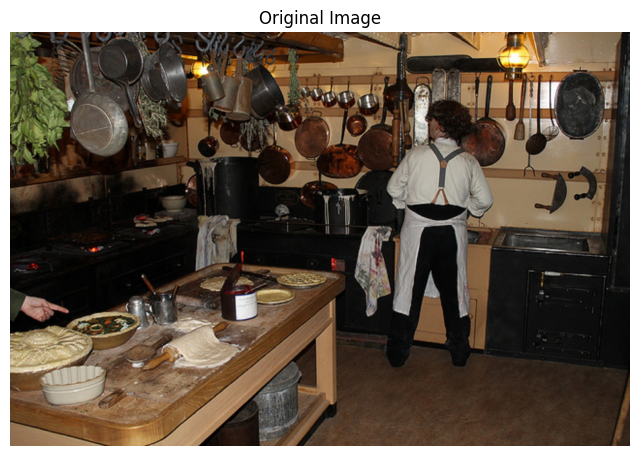

In [2]:
# 이미지 파일 경로 설정
img_path = "./assets/inputs/image.jpg"

# 이미지 읽기 (BGR 색상 순서로 로드됨)
frame = cv2.imread(img_path)

# 이미지 읽기 확인
if frame is None:
    print(f"Error: Cannot read image: {img_path}")
else:
    print(f"Image size: {frame.shape}")  # (높이, 너비, 채널)
    
    # 이미지 표시를 위한 함수
    def show_image(img, title="Image", figsize=(8, 6)):
        plt.figure(figsize=figsize)
        if len(img.shape) == 3:
            # BGR to RGB 변환
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.imshow(img_rgb)
        else:
            plt.imshow(img, cmap='gray')
        plt.title(title)
        plt.axis('off')
        plt.show()
    
    # 원본 이미지 표시
    show_image(frame, "Original Image")

### AI 모델용 이미지 전처리 예제

실제 AI 모델에서 사용되는 이미지 전처리 과정을 살펴보겠습니다.

Original image size: (1080, 1618)


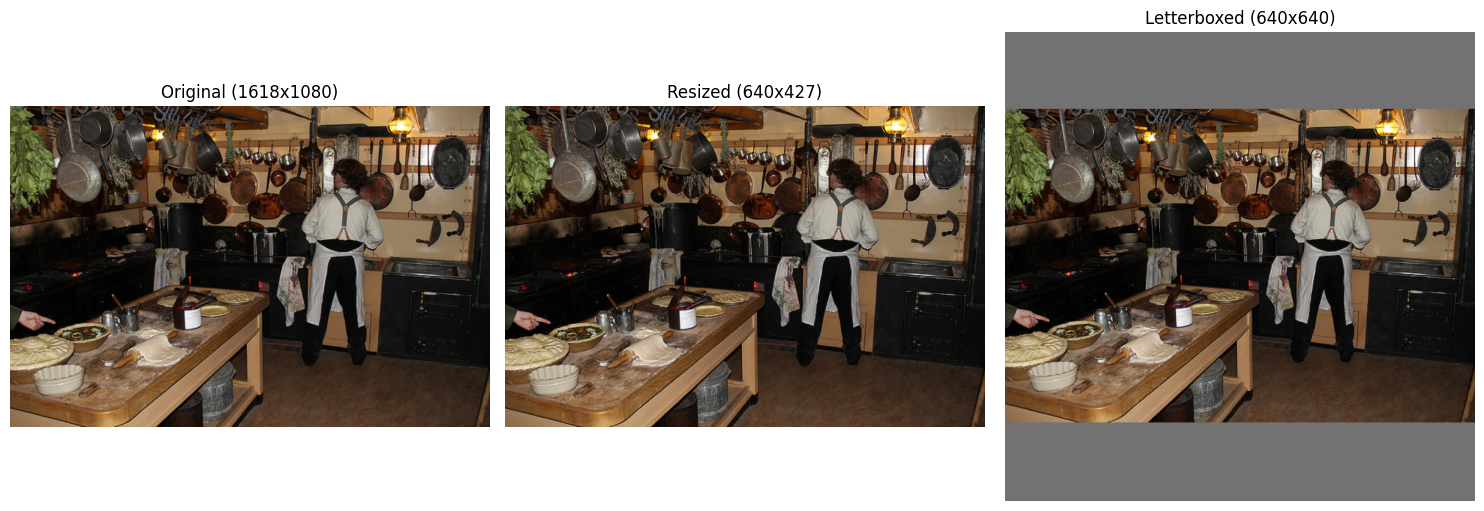

Resize ratio: 0.396
Padding (dw, dh): (0.0, 106.5)


In [3]:
# 이미지가 정상적으로 로드된 경우에만 실행
if frame is not None:
    # 원본 이미지 크기 확인
    src_shape = frame.shape[:2]  # (height, width)
    print(f"Original image size: {src_shape}")
    
    # AI 모델 입력을 위한 전처리
    new_shape = (640, 640)
    r = min(new_shape[0] / src_shape[0], new_shape[1] / src_shape[1])
    ratio = r, r
    
    # 비율을 유지하면서 리사이즈
    new_unpad = int(round(src_shape[1] * r)), int(round(src_shape[0] * r))
    resized = cv2.resize(frame, new_unpad, interpolation=cv2.INTER_LINEAR)
    
    # 패딩 추가 (letterbox)
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
    dw /= 2
    dh /= 2
    
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    image_input = cv2.copyMakeBorder(resized, top, bottom, left, right, 
                                    cv2.BORDER_CONSTANT, value=(114,114,114))
    
    # BGR → RGB 변환 (대부분의 AI 모델은 RGB 입력을 기대함)
    image_input_rgb = cv2.cvtColor(image_input, cv2.COLOR_BGR2RGB)
    
    # 전처리 결과 비교
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # 원본 이미지
    axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Original ({frame.shape[1]}x{frame.shape[0]})")
    axes[0].axis('off')
    
    # 리사이즈된 이미지
    axes[1].imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Resized ({resized.shape[1]}x{resized.shape[0]})")
    axes[1].axis('off')
    
    # 패딩이 추가된 최종 이미지
    axes[2].imshow(image_input_rgb)
    axes[2].set_title(f"Letterboxed ({image_input.shape[1]}x{image_input.shape[0]})")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Resize ratio: {r:.3f}")
    print(f"Padding (dw, dh): ({dw:.1f}, {dh:.1f})")

**핵심 포인트:**
- `cv2.imread()`로 이미지를 읽으면 BGR 순서로 로드됨
- AI 모델 입력 시 보통 RGB 변환이 필요: `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)`
- 모델 입력 크기에 맞게 비율을 유지하며 리사이즈 + 패딩 처리

---

## 2. 동영상 파일 입력 처리

### 기본 동영상 읽기

In [4]:
# 동영상 파일 경로 설정
video_path = "./assets/inputs/video.mp4"  # 실제 동영상 파일 경로로 변경하세요

# VideoCapture 객체 생성 (파일 경로 사용)
cap = cv2.VideoCapture(video_path)

if cap.isOpened():
    # 동영상 정보 확인
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    print(f"FPS: {fps}")
    print(f"Resolution: {width}x{height}")
    print(f"Total frames: {total_frames}")
    
    cap.release()

FPS: 30.0
Resolution: 960x540
Total frames: 303


### 동영상 프레임별 처리 예제

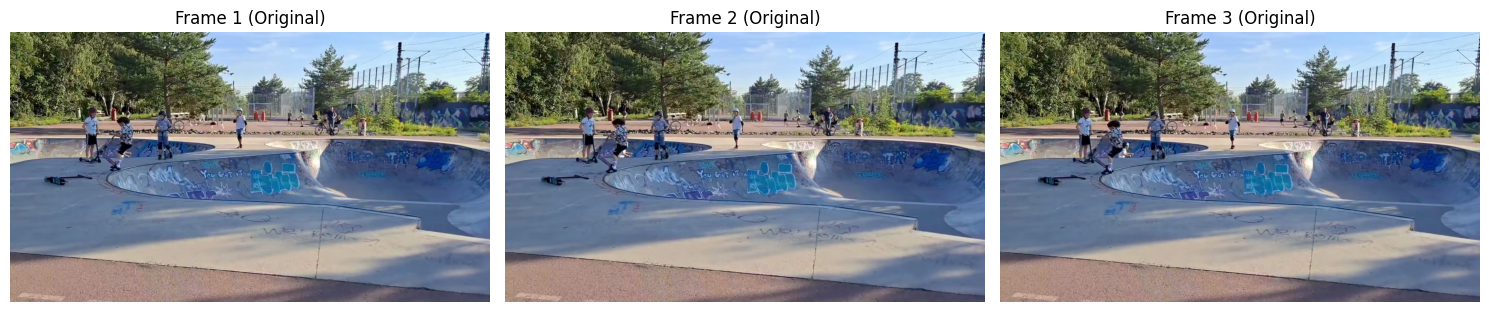

Processed 3 frames total


In [5]:
def process_video_frames(video_path, max_frames=10):
    """
    동영상의 프레임들을 읽어서 처리하는 함수
    """
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print(f"Error: Cannot open video: {video_path}")
        return
    
    frame_count = 0
    frames_to_show = []
    
    # 프레임별 처리 루프
    while True:
        ret, frame = cap.read()  # 프레임 읽기
        
        if not ret:  # 더 이상 읽을 프레임이 없으면 종료
            print("End of video reached.")
            break
        
        # 처리할 프레임 수 제한 (노트북에서의 출력을 위해)
        if frame_count >= max_frames:
            break
            
        # 여기서 프레임 처리 (예: 엣지 검출)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        edges = cv2.Canny(gray, 50, 150)
        
        # 처리된 프레임 저장 (시각화용)
        frames_to_show.append((frame, edges))
        
        frame_count += 1
    
    cap.release()
    
    # 결과 시각화
    if frames_to_show:
        fig, axes = plt.subplots(1, len(frames_to_show), figsize=(15, 6))
        
        for i, (original, processed) in enumerate(frames_to_show):
            # 원본 프레임
            axes[i].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
            axes[i].set_title(f'Frame {i+1} (Original)')
            axes[i].axis('off')
        
        plt.tight_layout()
        plt.show()
    
    print(f"Processed {frame_count} frames total")

# 동영상 처리 실행
if os.path.exists(video_path):
    process_video_frames(video_path, 3)
else:
    print(f"Video file not found: {video_path}")

---

## 3. 카메라(웹캠) 입력 처리

### 기본 웹캠 사용

**주의:** 웹캠 코드는 Jupyter Notebook에서 직접 실행하기 어려울 수 있습니다. 실제 환경에서는 별도의 Python 스크립트로 실행하는 것을 권장합니다.

In [6]:
def test_camera_availability():
    """
    사용 가능한 카메라 장치를 확인하는 함수
    """
    print("Checking camera devices...")
    
    # 방법 1: 장치 파일 경로로 확인
    camDevice = "/dev/video0"
    cap = cv2.VideoCapture(camDevice)
    if cap.isOpened():
        ret, frame = cap.read()
        if ret:
            print(f"Camera: {camDevice} Available ({frame.shape[1]}x{frame.shape[0]})")
        else:
            print(f"Camera: {camDevice} Detected but cannot read frame")
        cap.release()
    else:
        print(f"Camera: {camDevice} Not available")
    
    print("\nChecking other camera indices...")
    
    # 방법 2: 인덱스로 확인 (0~4번까지)
    for i in range(5):
        cap = cv2.VideoCapture(i)
        if cap.isOpened():
            ret, frame = cap.read()
            if ret:
                print(f"Camera {i}: Available ({frame.shape[1]}x{frame.shape[0]})")
            else:
                print(f"Camera {i}: Detected but cannot read frame")
            cap.release()
        else:
            print(f"Camera {i}: Not available")

# 카메라 확인
test_camera_availability()

Checking camera devices...
Camera: /dev/video0 Available (640x480)

Checking other camera indices...
Camera 0: Available (640x480)
Camera 1: Not available
Camera 2: Not available
Camera 3: Not available
Camera 4: Not available


[ WARN:0@4.861] global cap_v4l.cpp:913 open VIDEOIO(V4L2:/dev/video1): can't open camera by index
[ERROR:0@4.862] global obsensor_uvc_stream_channel.cpp:158 getStreamChannelGroup Camera index out of range
[ WARN:0@4.862] global cap_v4l.cpp:913 open VIDEOIO(V4L2:/dev/video2): can't open camera by index
[ERROR:0@4.863] global obsensor_uvc_stream_channel.cpp:158 getStreamChannelGroup Camera index out of range
[ WARN:0@4.863] global cap_v4l.cpp:913 open VIDEOIO(V4L2:/dev/video3): can't open camera by index
[ERROR:0@4.864] global obsensor_uvc_stream_channel.cpp:158 getStreamChannelGroup Camera index out of range
[ WARN:0@4.864] global cap_v4l.cpp:913 open VIDEOIO(V4L2:/dev/video4): can't open camera by index
[ERROR:0@4.865] global obsensor_uvc_stream_channel.cpp:158 getStreamChannelGroup Camera index out of range


In [7]:
# 웹캠 코드 예제 (참고용)
webcam_example_code = '''
import cv2

# VideoCapture 객체 생성 (카메라 인덱스 사용)
cap = cv2.VideoCapture(0)  # 0: 기본 카메라, 1: 두 번째 카메라

# 카메라 열기 확인
if not cap.isOpened():
    print("Error: Cannot open camera")
    exit(1)

print("Camera opened successfully. Press 'q' to quit.")

# 실시간 처리 루프
while True:
    ret, frame = cap.read()  # 실시간 프레임 읽기
    
    if not ret:
        print("Error: Cannot read frame")
        break
    
    # 여기서 AI 모델 추론 등 프레임 처리
    processed_frame = process_frame(frame)
    
    # 결과 화면에 표시
    cv2.imshow('Camera Feed', processed_frame)
    
    # 'q' 키로 종료
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# 리소스 해제
cap.release()
cv2.destroyAllWindows()
'''

print("웹캠 사용 예제 코드:")
print(webcam_example_code)

웹캠 사용 예제 코드:

import cv2

# VideoCapture 객체 생성 (카메라 인덱스 사용)
cap = cv2.VideoCapture(0)  # 0: 기본 카메라, 1: 두 번째 카메라

# 카메라 열기 확인
if not cap.isOpened():
    print("Error: Cannot open camera")
    exit(1)

print("Camera opened successfully. Press 'q' to quit.")

# 실시간 처리 루프
while True:
    ret, frame = cap.read()  # 실시간 프레임 읽기
    
    if not ret:
        print("Error: Cannot read frame")
        break
    
    # 여기서 AI 모델 추론 등 프레임 처리
    processed_frame = process_frame(frame)
    
    # 결과 화면에 표시
    cv2.imshow('Camera Feed', processed_frame)
    
    # 'q' 키로 종료
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

# 리소스 해제
cap.release()
cv2.destroyAllWindows()



### 카메라 설정 팁

In [8]:
def demonstrate_camera_settings():
    """
    카메라 설정 방법을 보여주는 함수
    """
    # 실제로는 카메라가 연결되어 있어야 작동합니다
    example_code = '''
# 카메라 해상도 설정
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

# FPS 설정
cap.set(cv2.CAP_PROP_FPS, 30)

# 자동 노출 설정
cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.25)

# 밝기 설정
cap.set(cv2.CAP_PROP_BRIGHTNESS, 50)
    '''
    
    print("카메라 설정 예제:")
    print(example_code)
    
    # 리눅스에서 카메라 장치 확인 방법
    print("\n리눅스에서 카메라 장치 확인:")
    print("터미널에서: ls /dev/video*")
    print("출력 예: /dev/video0  /dev/video1")
    print("→ cap = cv2.VideoCapture(0) 또는 cap = cv2.VideoCapture(1) 사용")

demonstrate_camera_settings()

카메라 설정 예제:

# 카메라 해상도 설정
cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)

# FPS 설정
cap.set(cv2.CAP_PROP_FPS, 30)

# 자동 노출 설정
cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.25)

# 밝기 설정
cap.set(cv2.CAP_PROP_BRIGHTNESS, 50)
    

리눅스에서 카메라 장치 확인:
터미널에서: ls /dev/video*
출력 예: /dev/video0  /dev/video1
→ cap = cv2.VideoCapture(0) 또는 cap = cv2.VideoCapture(1) 사용


---

## 4. 공통 전처리 함수

모든 입력 타입에서 AI 모델 사용 시 공통적으로 필요한 전처리 함수를 구현해보겠습니다.

In [9]:
def preprocess(image_src, new_shape=(640, 640), fill_color=(114, 114, 114), format=cv2.COLOR_BGR2RGB):
    """
    이미지 크기를 모델 입력 크기에 맞추되, 원본 비율을 유지하며 padding을 추가하는 전처리 함수
    
    Args:
        image_src: 입력 이미지 (numpy array, BGR)
        new_shape: 원하는 출력 크기 (기본 640x640)
        fill_color: padding 시 채울 색상 (기본 [114,114,114] = 회색)
        format: 색상 공간 변환 코드
    
    Returns:
        image_new: 전처리된 이미지
        ratio: 리사이즈 비율 (원본 좌표 복원용)
        pad: 패딩 크기 (원본 좌표 복원용)
    """
    # 원본 이미지의 높이, 너비
    src_shape = image_src.shape[:2]  # (height, width)
    
    # new_shape이 int라면 (width, height) 튜플로 변환
    if isinstance(new_shape, int):
        new_shape = (new_shape, new_shape)
    
    # 축소/확대 비율 계산 (종횡비 유지를 위해 더 작은 비율 선택)
    r = min(new_shape[0] / src_shape[0], new_shape[1] / src_shape[1])
    ratio = r, r
    
    # 비율 적용한 새 크기 (패딩 제외)
    new_unpad = int(round(src_shape[1] * r)), int(round(src_shape[0] * r))
    
    # 패딩 크기 계산
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
    dw /= 2  # 좌우 균등 분배
    dh /= 2  # 상하 균등 분배
    
    # 종횡비가 다르면 리사이즈 실행
    if src_shape[::-1] != new_unpad:
        image_src = cv2.resize(image_src, new_unpad, interpolation=cv2.INTER_LINEAR)
    
    # 패딩 적용
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    image_new = cv2.copyMakeBorder(
        image_src, top, bottom, left, right,
        cv2.BORDER_CONSTANT, value=fill_color
    )
    
    # 색상 변환 (BGR → RGB)
    if format is not None:
        image_new = cv2.cvtColor(image_new, format)
    
    return image_new, ratio, (dw, dh)

print("Preprocessing function has been defined.")

Preprocessing function has been defined.


### 전처리 함수 테스트

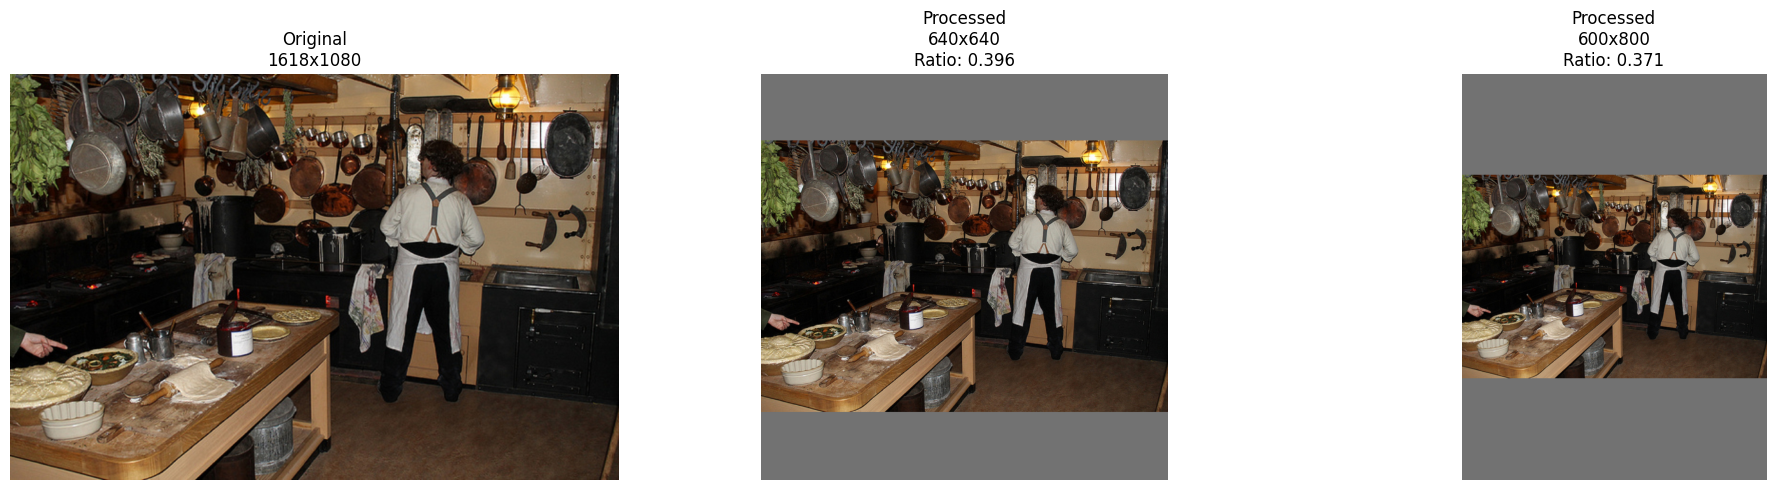

In [10]:
# 샘플 이미지로 전처리 함수 테스트
if 'frame' in locals() and frame is not None:
    # 다양한 크기로 전처리 테스트
    sizes = [(640, 640), (800, 600)]
    
    fig, axes = plt.subplots(1, len(sizes) + 1, figsize=(20, 5))
    
    # 원본 이미지
    axes[0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Original\n{frame.shape[1]}x{frame.shape[0]}")
    axes[0].axis('off')
    
    # 각 크기별 전처리 결과
    for i, size in enumerate(sizes):
        processed, ratio, pad = preprocess(frame, size, format=None)  # BGR 유지
        processed_rgb = cv2.cvtColor(processed, cv2.COLOR_BGR2RGB)
        
        axes[i+1].imshow(processed_rgb)
        axes[i+1].set_title(f"Processed\n{size[1]}x{size[0]}\nRatio: {ratio[0]:.3f}")
        axes[i+1].axis('off')
    
    plt.tight_layout()
    plt.show()
else:
    print("No test image available.")

---

## 5. 실습 예제

### 예제 1: 통합 입력 처리 함수

In [11]:
def create_input_source(source):
    """
    입력 소스에 따라 적절한 VideoCapture 객체를 생성하는 함수
    
    Args:
        source: 입력 소스
                - 정수: 카메라 인덱스 (예: 0, 1)
                - 문자열: 이미지/동영상 파일 경로
    
    Returns:
        cap: VideoCapture 객체
        source_type: 입력 타입 ("image", "video", "camera")
    """
    if isinstance(source, int):
        # 카메라 입력
        cap = cv2.VideoCapture(source)
        source_type = "camera"
    elif isinstance(source, str):
        if source.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            # 이미지 입력 (단일 프레임)
            cap = None
            source_type = "image"
        else:
            # 동영상 파일 입력
            cap = cv2.VideoCapture(source)
            source_type = "video"
    
    return cap, source_type

def process_frame_demo(frame):
    """
    데모용 프레임 처리 함수 - 엣지 검출
    """
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)

def process_input_demo(source, max_frames=5):
    """
    다양한 입력 소스를 통합적으로 처리하는 데모 함수
    """
    cap, source_type = create_input_source(source)
    
    print(f"Input type: {source_type}")
    
    if source_type == "image":
        # 이미지 처리
        frame = cv2.imread(source)
        if frame is None:
            print(f"Error: Cannot read image: {source}")
            return
        
        # 이미지 처리
        processed = process_frame_demo(frame)

        # 결과 표시
        plt.figure(figsize=(8, 6))
        plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        plt.title("Original")
        plt.axis('off')
        plt.show()
        
        print(f"Processing completed for image: {source}")
        
    else:
        # 동영상/카메라 처리
        if not cap.isOpened():
            print(f"Error: Cannot open {source}")
            return
        
        frame_count = 0
        frames_to_show = []
        
        while True:
            ret, frame = cap.read()
            if not ret:
                if source_type == "video":
                    print("Video processing completed")
                break
            
            if frame_count >= max_frames:
                break
            
            # 프레임 처리
            processed = process_frame_demo(frame)
            
            # 시각화용 저장
            frames_to_show.append((frame, processed))
            frame_count += 1
        
        cap.release()
        
        # 결과 시각화
        if frames_to_show:
            fig, axes = plt.subplots(1, len(frames_to_show), figsize=(15, 6))
            if len(frames_to_show) == 1:
                axes = axes.reshape(-1, 1)
            
            for i, (original, processed) in enumerate(frames_to_show):
                axes[i].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
                axes[i].set_title(f'Frame {i+1} (Original)')
                axes[i].axis('off')
                
            plt.tight_layout()
            plt.show()

print("Unified input processing functions have been defined.")

Unified input processing functions have been defined.


### 실습: 다양한 입력 소스 테스트

=== Image processing test ===
Input type: image


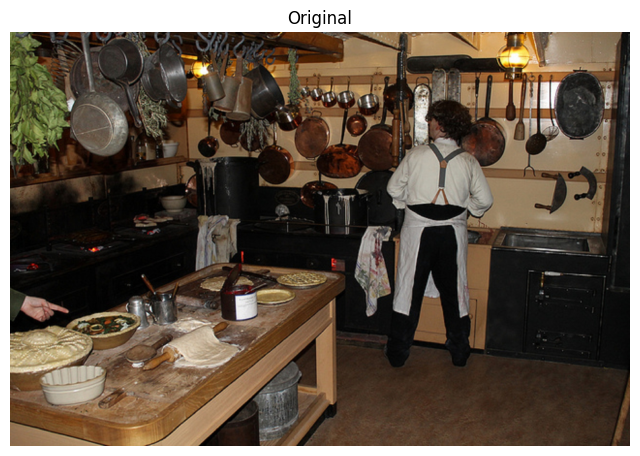

Processing completed for image: ./assets/inputs/image.jpg


In [12]:
# 1. 이미지 처리 테스트
# 1. 이미지 처리 테스트
if 'img_path' in locals() and os.path.exists(img_path):
    print("=== Image processing test ===")
    process_input_demo(img_path)
else:
    print("No test image found.")

=== Video processing test ===
Input type: video


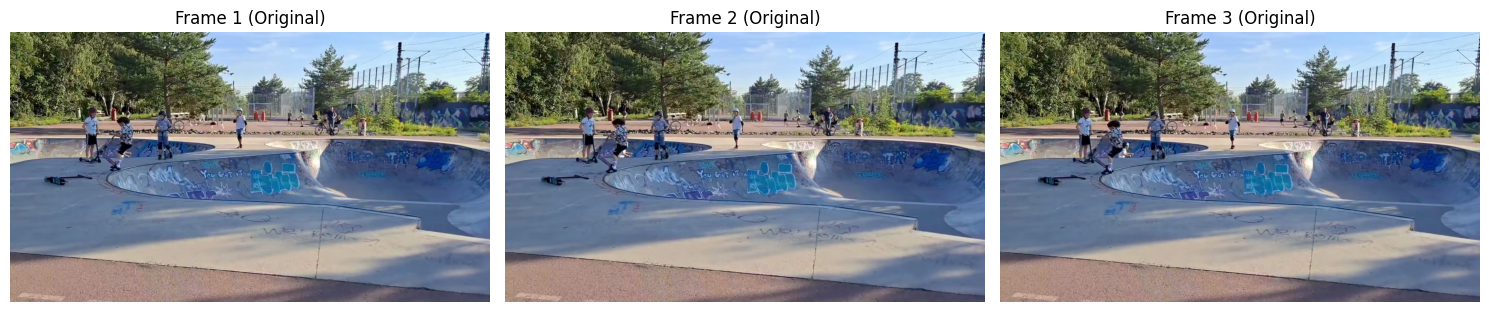

In [13]:
# 2. 동영상 처리 테스트
if os.path.exists(video_path):
    print("=== Video processing test ===")
    process_input_demo(video_path, max_frames=3)
else:
    print("No test video found.")

### 예제 2: 배치 이미지 처리 클래스

In [14]:
class InputProcessor:
    def __init__(self, model_input_size=(640, 640)):
        self.model_input_size = model_input_size
        
    def setup_camera(self, camera_index=0):
        """카메라 최적 설정"""
        cap = cv2.VideoCapture(camera_index)
        
        # 해상도 및 FPS 설정
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
        cap.set(cv2.CAP_PROP_FPS, 30)
        
        # 자동 조정 끄기 (안정적인 처리를 위해)
        cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.25)
        
        return cap
    
    def setup_video(self, video_path):
        """동영상 파일 설정"""
        cap = cv2.VideoCapture(video_path)
        
        # 동영상 정보 확인
        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        
        print(f"Video info - FPS: {fps}, Total frames: {total_frames}")
        
        return cap
    
    def process_single_frame(self, frame):
        """단일 프레임 처리 (사용자 정의 가능)"""
        # 전처리
        processed, ratio, pad = preprocess(frame, self.model_input_size)
        
        # 여기에 AI 모델 추론 로직을 추가할 수 있습니다
        # result = model.inference(processed)
        
        # 데모용으로 간단한 필터 적용
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        edges = cv2.Canny(gray, 50, 150)
        return cv2.cvtColor(edges, cv2.COLOR_GRAY2BGR)
    
    def create_sample_images(self, output_dir="sample_images", num_images=5):
        """테스트용 샘플 이미지들을 생성"""
        os.makedirs(output_dir, exist_ok=True)
        
        for i in range(num_images):
            # 다양한 패턴의 샘플 이미지 생성
            img = np.zeros((400, 600, 3), dtype=np.uint8)
            
            # 배경색 랜덤
            bg_color = tuple(np.random.randint(0, 100, 3).tolist())
            img[:] = bg_color
            
            # 랜덤 도형들 추가
            for _ in range(5):
                color = tuple(np.random.randint(100, 255, 3).tolist())
                center = (np.random.randint(50, 550), np.random.randint(50, 350))
                radius = np.random.randint(20, 80)
                cv2.circle(img, center, radius, color, -1)
            
            # 텍스트 추가
            cv2.putText(img, f'Sample {i+1}', (50, 50), 
                       cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
            
            # 저장
            filename = os.path.join(output_dir, f"sample_{i+1:03d}.jpg")
            cv2.imwrite(filename, img)
        
        print(f"Created {num_images} sample images in '{output_dir}' directory.")
        return output_dir
    
    def process_batch_images(self, image_folder, max_display=3):
        """이미지 폴더 일괄 처리"""
        # 지원하는 이미지 확장자
        extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp']
        
        image_files = []
        for ext in extensions:
            image_files.extend(glob.glob(os.path.join(image_folder, ext)))
        
        print(f"Processing {len(image_files)} images in total.")
        
        processed_results = []
        
        for i, img_path in enumerate(image_files):
            print(f"Processing... ({i+1}/{len(image_files)}): {img_path}")
            
            frame = cv2.imread(img_path)
            if frame is None:
                print(f"Warning: Cannot read {img_path}.")
                continue
            
            # 이미지 처리
            processed = self.process_single_frame(frame)
            
            # 시각화용 저장 (일부만)
            if len(processed_results) < max_display:
                processed_results.append((frame, processed, os.path.basename(img_path)))
        
        print("Batch processing completed!")
        
        # 결과 시각화
        if processed_results:
            fig, axes = plt.subplots(2, len(processed_results), figsize=(15, 8))
            if len(processed_results) == 1:
                axes = axes.reshape(-1, 1)
            
            for i, (original, processed, filename) in enumerate(processed_results):
                axes[0, i].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
                axes[0, i].set_title(f'Original: {filename}')
                axes[0, i].axis('off')
                
                axes[1, i].imshow(cv2.cvtColor(processed, cv2.COLOR_BGR2RGB))
                axes[1, i].set_title(f'Processed: {filename}')
                axes[1, i].axis('off')
            
            plt.tight_layout()
            plt.show()

# InputProcessor 클래스 인스턴스 생성
processor = InputProcessor()
print("InputProcessor class has been defined.")

InputProcessor class has been defined.


### 배치 처리 테스트

Created 3 sample images in 'sample_images' directory.
Processing 3 images in total.
Processing... (1/3): sample_images/sample_002.jpg
Processing... (2/3): sample_images/sample_003.jpg
Processing... (3/3): sample_images/sample_001.jpg
Batch processing completed!


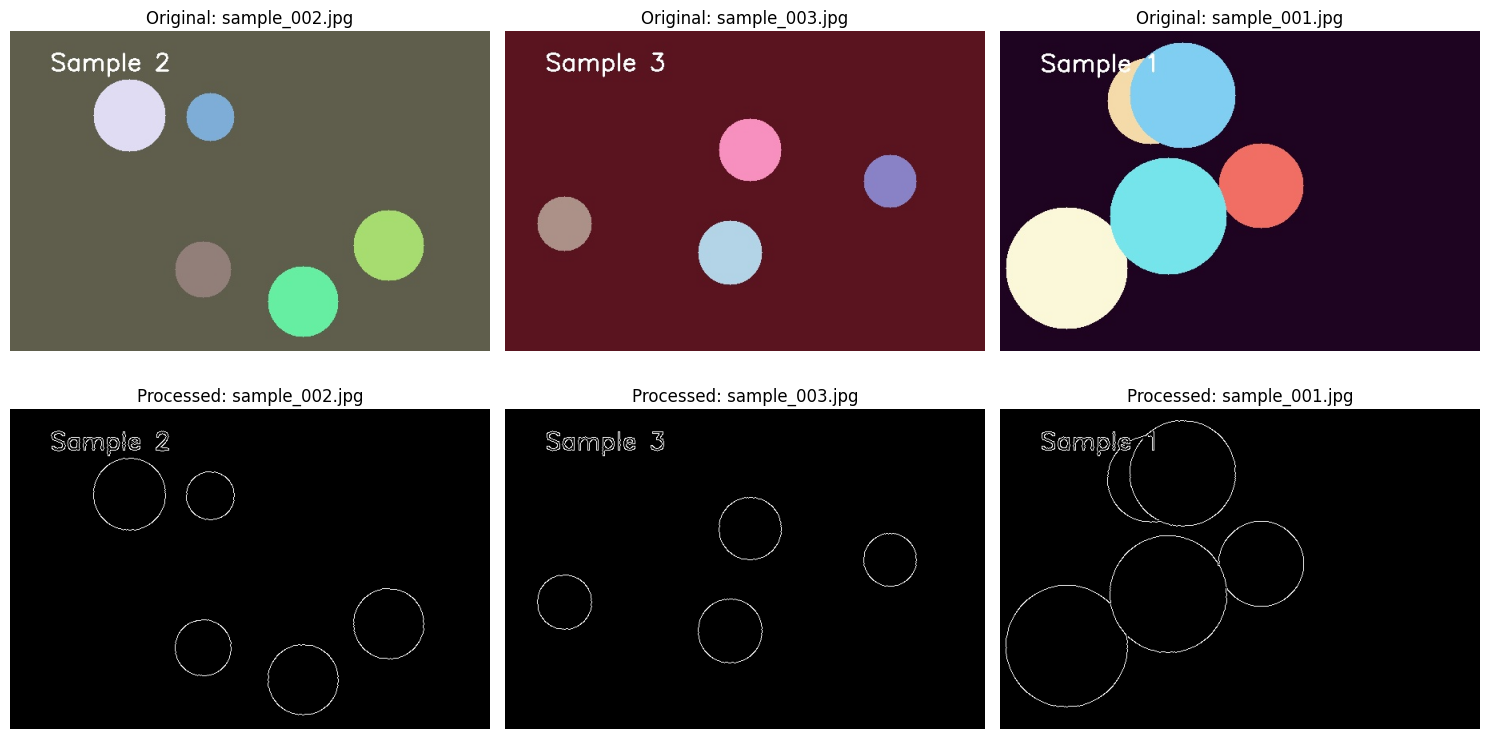

In [15]:
# 샘플 이미지 생성 및 배치 처리 테스트
sample_dir = processor.create_sample_images(num_images=3)
processor.process_batch_images(sample_dir)

---

## 핵심 정리

### 1. 입력 타입별 특징
| 입력 타입 | 함수 | 특징 | 주의사항 |
|----------|------|------|----------|
| **이미지** | `cv2.imread()` | 단일 프레임, 높은 품질 | 파일 존재 여부 확인 필수 |
| **동영상** | `cv2.VideoCapture(파일경로)` | 연속 프레임, 시간 정보 | 코덱 호환성 확인 |
| **카메라** | `cv2.VideoCapture(인덱스)` | 실시간 입력, 인터랙티브 | 장치 인덱스 확인 필요 |

### 2. 공통 처리 패턴
```python
# 1. 입력 소스 초기화
source = initialize_input()

# 2. 프레임별 처리 루프
while True:
    frame = get_next_frame(source)
    if frame is None:
        break
    
    # 3. AI 모델용 전처리
    preprocessed = preprocess(frame)
    
    # 4. 모델 추론
    result = model.inference(preprocessed)
    
    # 5. 후처리 및 시각화
    output = postprocess(frame, result)
    
    # 6. 결과 출력/저장
    save_or_display(output)

# 7. 리소스 해제
cleanup(source)
```